# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Maulana Rhys Pradana | 5054251041 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

In [2]:
df = pd.read_csv('data-selected-columns.csv') 

print("Info Dataset:")
df.info()
print("\nStatistik Deskriptif:")
display(df.describe())
print("\nJMissing Value:")
print(df.isnull().sum())

Info Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   569 non-null    int64  
 1   diagnosis            569 non-null    object 
 2   radius_mean          569 non-null    float64
 3   texture_mean         569 non-null    float64
 4   perimeter_mean       569 non-null    float64
 5   area_mean            569 non-null    float64
 6   smoothness_mean      569 non-null    float64
 7   compactness_mean     569 non-null    float64
 8   concavity_mean       569 non-null    float64
 9   concave points_mean  569 non-null    float64
dtypes: float64(8), int64(1), object(1)
memory usage: 44.6+ KB

Statistik Deskriptif:


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200



JMissing Value:
id                     0
diagnosis              0
radius_mean            0
texture_mean           0
perimeter_mean         0
area_mean              0
smoothness_mean        0
compactness_mean       0
concavity_mean         0
concave points_mean    0
dtype: int64


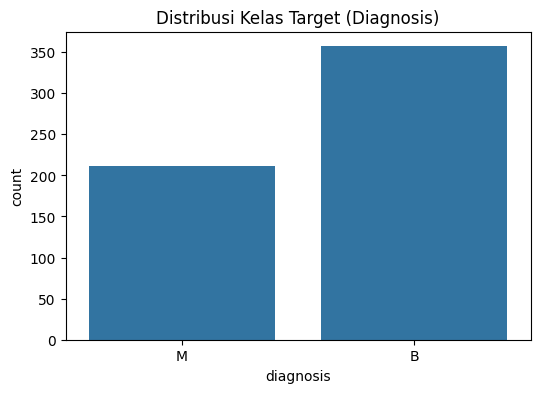

In [3]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='diagnosis')
plt.title('Distribusi Kelas Target (Diagnosis)')
plt.show()

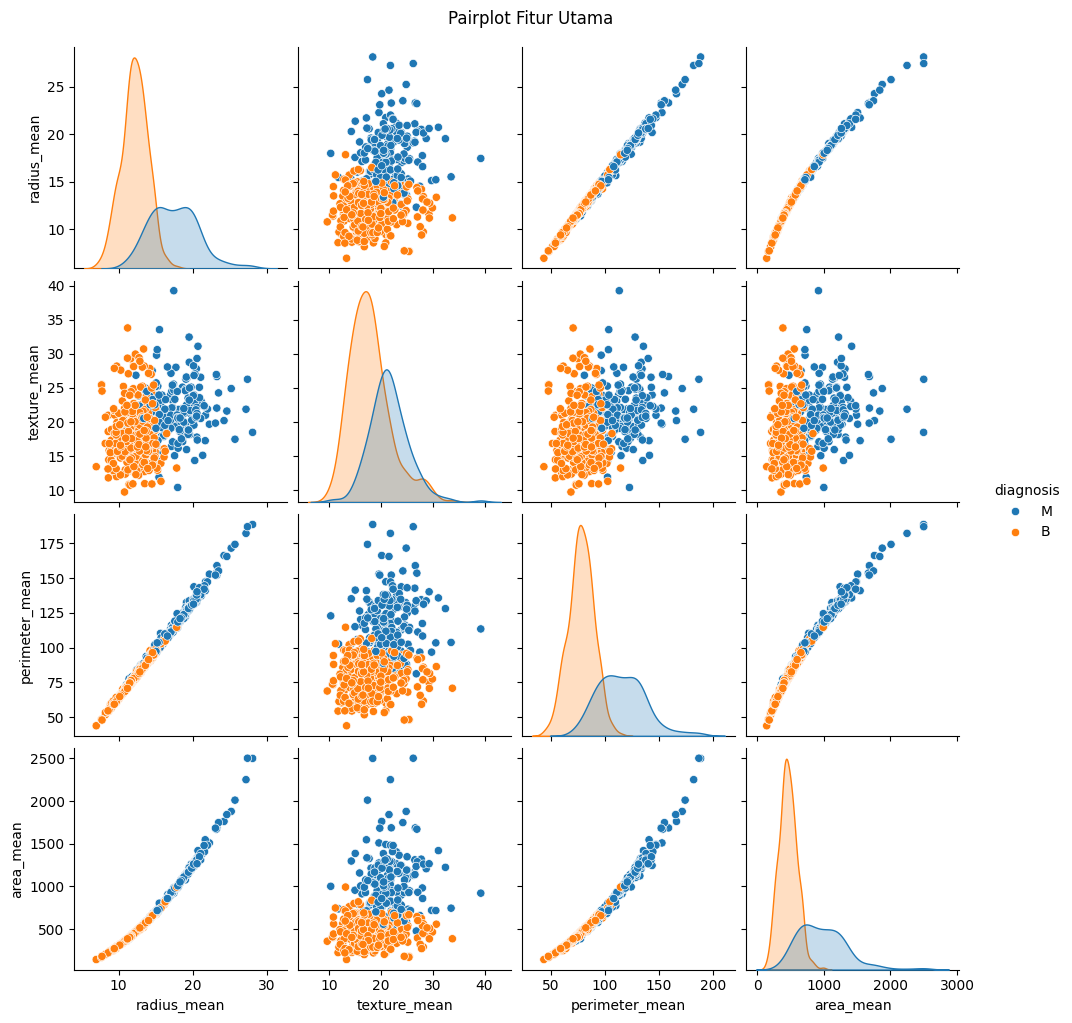

In [4]:
features_to_plot = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'diagnosis']
sns.pairplot(df[features_to_plot], hue='diagnosis', diag_kind='kde')
plt.suptitle('Pairplot Fitur Utama', y=1.02)
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [5]:
if 'Unnamed: 32' in df.columns:
    df = df.drop('Unnamed: 32', axis=1)
    
if 'id' in df.columns:
    df = df.drop('id', axis=1)

In [6]:
le = LabelEncoder()
df['diagnosis'] = le.fit_transform(df['diagnosis']) 

In [7]:
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Eksperimen Model

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [9]:
svm_linear = SVC(kernel='linear', random_state=42)
svm_linear.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [10]:
y_pred_linear = svm_linear.predict(X_test_scaled)

## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [11]:
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [12]:
y_pred_rbf = svm_rbf.predict(X_test_scaled)

## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [13]:
C_values = [0.01, 0.1, 1, 10, 100]
train_acc = []
test_acc = []

In [14]:
for c in C_values:
    model = SVC(kernel='rbf', C=c, gamma='scale', random_state=42)
    model.fit(X_train_scaled, y_train)
    
    train_acc.append(accuracy_score(y_train, model.predict(X_train_scaled)))
    test_acc.append(accuracy_score(y_test, model.predict(X_test_scaled)))

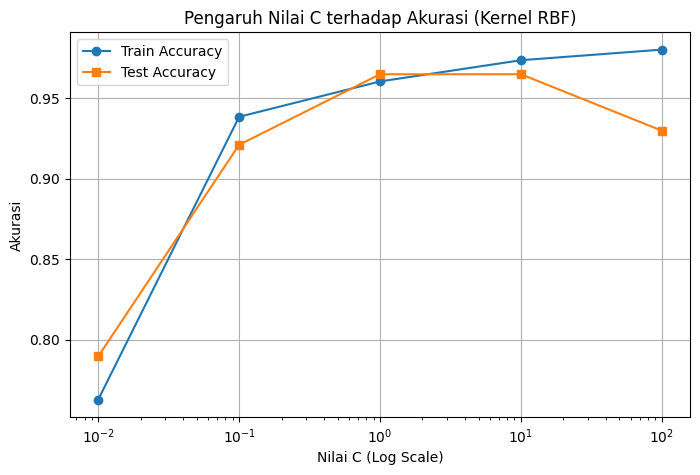

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(C_values, train_acc, label='Train Accuracy', marker='o')
plt.plot(C_values, test_acc, label='Test Accuracy', marker='s')
plt.xscale('log')
plt.title('Pengaruh Nilai C terhadap Akurasi (Kernel RBF)')
plt.xlabel('Nilai C (Log Scale)')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)
plt.show()

# 4. Evaluasi Model

In [16]:
def get_metrics(y_true, y_pred, model_name):
    return [model_name, 
            accuracy_score(y_true, y_pred), 
            precision_score(y_true, y_pred), 
            recall_score(y_true, y_pred), 
            f1_score(y_true, y_pred)]

metrics_data = [
    get_metrics(y_test, y_pred_linear, 'SVM Linear'),
    get_metrics(y_test, y_pred_rbf, 'SVM RBF')
]

df_metrics = pd.DataFrame(metrics_data, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
display(df_metrics)

,Model,Accuracy,Precision,Recall,F1-Score
0,SVM Linear,0.929825,0.886364,0.928571,0.906977
1,SVM RBF,0.964912,0.952381,0.952381,0.952381


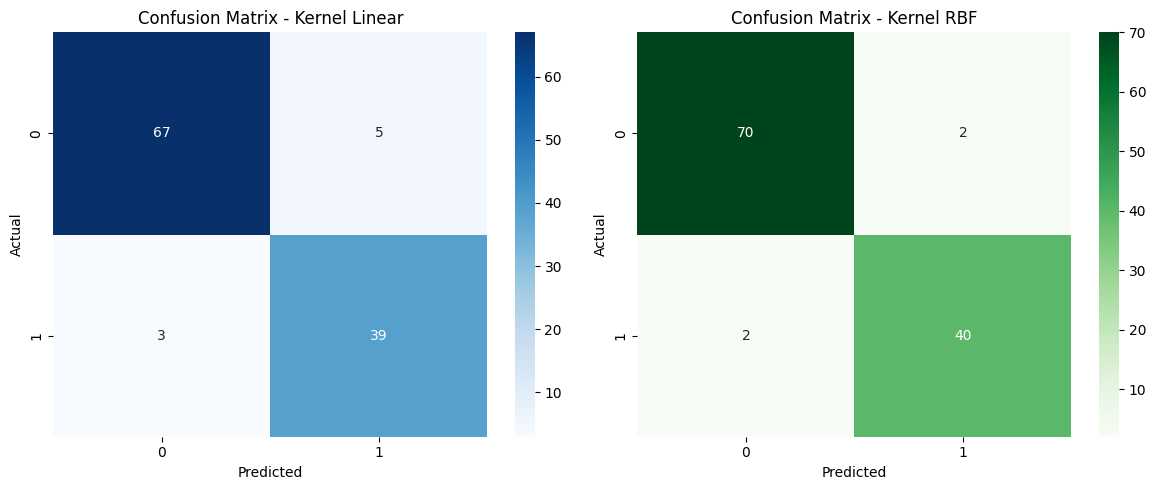

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_linear), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix - Kernel Linear')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_rbf), annot=True, fmt='d', cmap='Greens', ax=ax[1])
ax[1].set_title('Confusion Matrix - Kernel RBF')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [18]:
print(f"Jumlah Support Vectors (Kernel Linear) : {np.sum(svm_linear.n_support_)}")
print(f"Jumlah Support Vectors (Kernel RBF)    : {np.sum(svm_rbf.n_support_)}")

Jumlah Support Vectors (Kernel Linear) : 69
Jumlah Support Vectors (Kernel RBF)    : 102


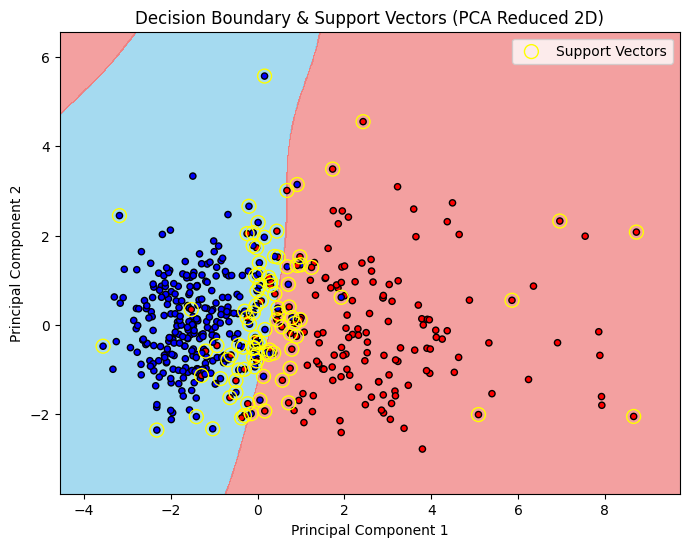

In [19]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

svm_pca = SVC(kernel='rbf', C=1, gamma='scale').fit(X_train_pca, y_train)

X1, X2 = np.meshgrid(np.arange(start = X_train_pca[:, 0].min() - 1, stop = X_train_pca[:, 0].max() + 1, step = 0.02),
                     np.arange(start = X_train_pca[:, 1].min() - 1, stop = X_train_pca[:, 1].max() + 1, step = 0.02))

plt.figure(figsize=(8, 6))
plt.contourf(X1, X2, svm_pca.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape), 
             alpha = 0.75, cmap = ListedColormap(('skyblue', 'lightcoral')))

plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap=ListedColormap(('blue', 'red')), edgecolors='k', s=20)
plt.scatter(svm_pca.support_vectors_[:, 0], svm_pca.support_vectors_[:, 1], s=100, linewidth=1, facecolors='none', edgecolors='yellow', label='Support Vectors')

plt.title('Decision Boundary & Support Vectors (PCA Reduced 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa SVM dengan kernel Linear vs RBF. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian, dikaitkan dengan bentuk sebaran data pada EDA?
- Jelaskan temuan dari eksperimen regularisasi (nilai `C`). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Bandingkan jumlah support vectors antara model Linear dan RBF. Apa hubungan jumlah support vectors dengan kompleksitas batas keputusan yang terbentuk?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

### Jawabam:
A. Kernel Linear vs RBF: 

Performa kedua kernel umumnya tidak berbeda drastis karena berdasarkan hasil pairplot pada Exploratory Data Analysis (EDA), fitur-fitur utama (seperti radius_mean dan area_mean) sudah membentuk klaster yang cenderung terpisah secara linear antar kelas diagnosis. Hal ini membuat batas lurus dari kernel Linear sudah cukup efektif.

B. Eksperimen Regularisasi (Nilai C): 

Ketika nilai C terlampau kecil, model rentan mengalami underfitting akibat margin yang terlalu toleran terhadap kesalahan. Sebaliknya, saat nilai C terus diperbesar (menjadi hard-margin), model mulai menunjukkan gejala overfitting yang ditandai dengan garis akurasi training yang terus melesat naik mendekati 100%, sementara akurasi testing menjadi stagnan atau bahkan perlahan menurun.

C. Jumlah Support Vectors: 

Kernel RBF memetakan data ke dimensi lebih tinggi sehingga umumnya menghasilkan jumlah support vectors yang lebih banyak dibandingkan kernel Linear. Semakin banyak jumlah support vectors yang dipertahankan, maka bentuk batas keputusan (decision boundary) model akan semakin kompleks, berliku, dan berisiko menghafal noise dari himpunan data latih.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba kernel Polynomial, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

### jawaban :
Kesimpulan:

Algoritma Support Vector Machine (SVM) terbukti sangat kapabel untuk diimplementasikan pada masalah klasifikasi diagnosis medis seperti pada dataset Breast Cancer berjumlah 569 observasi ini. Tahapan feature scaling (seperti Standardisasi) merupakan tahap yang paling krusial untuk algoritma berbasis jarak seperti SVM, mengingat rentang nilai fitur sangat timpang, misalnya smoothness_mean yang berada di rentang desimal kecil melawan area_mean yang mencapai angka ribuan.

Saran:

Untuk pengembangan selanjutnya, disarankan untuk mengotomatiskan pencarian hyperparameter menggunakan modul pencarian GridSearchCV agar mendapatkan kombinasi absolut terbaik antara nilai C dan gamma. Selain itu, uji coba perbandingan menggunakan algoritma berbasis tree (seperti Decision Tree atau XGBoost) dapat dilakukan untuk melihat apakah algoritma tersebut mampu melampaui metrik evaluasi SVM tanpa harus melalui tahapan feature scaling yang sensitif.